# 06 — Overture Maps EDA (buildings + places)

**Goal.** Inventory every attribute available in the public Overture release we use for ground truth, then measure **fill rates, class/subtype distributions, and source effects** on compact city extracts.

**Scope.**
1. Buildings schema feature catalog (`subtype`, `class`, height/floors, façade/roof, sources, …)
2. Live DuckDB queries against S3 GeoParquet (`2026-08-19.0`)
3. Places POIs as a noisy-GT complement (schools / hospitals)
4. Mapping to this project's study taxonomy (binary + 10-class)
5. **US hierarchy EDA** — 15 downtown boxes, rolled to state / Census region
6. **Every US city** — Census place polygons for the 50 states + DC, then the same rollup

**Requires.** Network access to public Overture S3. No Earth Engine.

**Docs.** [Buildings guide](https://docs.overturemaps.org/guides/buildings/) · [Building schema](https://docs.overturemaps.org/schema/reference/buildings/building/) · [BuildingSubtype](https://docs.overturemaps.org/schema/reference/buildings/types/building_subtype/) · [BuildingClass](https://docs.overturemaps.org/schema/reference/buildings/types/building_class/) · [Places](https://docs.overturemaps.org/guides/places/)


## Setup

```bash
pip install -r requirements.txt
```

Run from the **repo root** so `outputs/overture_eda/` is created next to other outputs.


In [2]:
from __future__ import annotations

import json
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

pd.set_option("display.max_rows", 80)
pd.set_option("display.max_colwidth", 100)
pd.set_option("display.float_format", lambda x: f"{x:0.2f}")

ROOT = Path(".").resolve()
if not (ROOT / "requirements.txt").exists() and (ROOT.parent / "requirements.txt").exists():
    ROOT = ROOT.parent

OUT = ROOT / "outputs" / "overture_eda"
OUT.mkdir(parents=True, exist_ok=True)

RELEASE = "2026-08-19.0"
BUILDINGS = f"s3://overturemaps-us-west-2/release/{RELEASE}/theme=buildings/type=building/*"
PLACES = f"s3://overturemaps-us-west-2/release/{RELEASE}/theme=places/type=place/*"

# Compact inner-city extracts (cheap queries; not full metros)
CITIES: dict[str, tuple[float, float, float, float]] = {
    # US (also used in notebooks 02–05)
    "Boston": (-71.18, 42.30, -71.02, 42.40),
    "Houston": (-95.45, 29.72, -95.30, 29.80),
    "Chicago": (-87.70, 41.84, -87.58, 41.92),
    "SF": (-122.45, 37.74, -122.38, 37.81),
    # Europe (high OSM label density)
    "Amsterdam": (4.85, 52.35, 4.95, 52.40),
    "Berlin": (13.35, 52.48, 13.50, 52.55),
    # Global South (sparse labels)
    "Nairobi": (36.75, -1.35, 36.90, -1.25),
    "Lagos": (3.35, 6.45, 3.50, 6.55),
}

con = duckdb.connect()
con.execute("INSTALL httpfs; LOAD httpfs;")
con.execute("SET s3_region='us-west-2';")
con.execute("SET enable_progress_bar=false;")


def bbox_where(xmin: float, ymin: float, xmax: float, ymax: float) -> str:
    return (
        f"bbox.xmin > {xmin} AND bbox.xmax < {xmax} "
        f"AND bbox.ymin > {ymin} AND bbox.ymax < {ymax}"
    )


print("ROOT:", ROOT)
print("OUT:", OUT)
print("DuckDB ready · release", RELEASE)
print("Cities:", list(CITIES))


ROOT: /data/users/kv133/Alpha-Earth-Embeddings-Research
OUT: /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/overture_eda
DuckDB ready · release 2026-08-19.0
Cities: ['Boston', 'Houston', 'Chicago', 'SF', 'Amsterdam', 'Berlin', 'Nairobi', 'Lagos']


## 1. Buildings feature catalog

Overture `theme=buildings` / `type=building` conflates OSM + Esri/cadastre + Microsoft / Google ML footprints (~2.5–2.6B). **Use labels (`subtype` / `class`) come from OSM only** — ML footprints contribute geometry but almost never use tags.

| Field | Type | Role for this project |
|---|---|---|
| `id` | string (GERS) | Stable building ID |
| `geometry` | Polygon / MultiPolygon | Footprint / roofprint |
| `bbox` | struct xmin/xmax/ymin/ymax | Spatial filter (partition prune) |
| `theme` / `type` | `"buildings"` / `"building"` | Hive partitions |
| `version` | int | Feature version |
| `sources` | list[struct] | Provenance (`dataset`, `record_id`, …) |
| `names` | struct | Optional building name |
| **`subtype`** | enum (13) | **Broad use** — primary binary GT |
| **`class`** | enum (~90) | **Fine OSM-style use** — multi-class GT |
| `height` | float (m) | Weak 3D prior |
| `min_height` | float (m) | Elevated parts |
| `num_floors` | int | Weak 3D prior |
| `num_floors_underground` | int | Rare |
| `min_floor` | int | Floating parts |
| `level` | int | Relative level |
| `is_underground` | bool | Rare |
| `has_parts` | bool | Link to `building_part` features |
| `facade_color` / `facade_material` | string | Rare OSM cosmetics |
| `roof_material` / `roof_shape` / `roof_color` / `roof_height` / `roof_direction` / `roof_orientation` | mixed | Rare OSM roof tags |

### `subtype` values (13)

`agricultural` · `civic` · `commercial` · `education` · `entertainment` · `industrial` · `medical` · `military` · `outbuilding` · `religious` · `residential` · `service` · `transportation`

### `class` (high-precision subset used in notebooks 03–05)

Mapped into a 10-way study taxonomy; ambiguous tags (`residential`, `terrace`, bare `building=yes`) are **excluded** from gold multi-class GT.


In [3]:
# Live schema from the public release
schema = con.execute(
    f"DESCRIBE SELECT * FROM read_parquet('{BUILDINGS}', hive_partitioning=1) LIMIT 0"
).df()[["column_name", "column_type"]]
schema.to_csv(OUT / "buildings_schema.csv", index=False)
print(f"{len(schema)} columns in buildings parquet\n")
schema


26 columns in buildings parquet



,column_name,column_type
0,id,VARCHAR
1,names,"STRUCT(""primary"" VARCHAR, common MAP(VARCHAR, VARCHAR), rules STRUCT(variant VARCHAR, ""language""..."
2,sources,"STRUCT(property VARCHAR, dataset VARCHAR, license VARCHAR, record_id VARCHAR, update_time VARCHA..."
3,level,INTEGER
4,height,DOUBLE
5,min_height,DOUBLE
6,is_underground,BOOLEAN
7,num_floors,INTEGER
8,num_floors_underground,INTEGER
9,min_floor,INTEGER


In [4]:
# Official subtype + study-relevant class inventories
SUBTYPES = [
    "agricultural", "civic", "commercial", "education", "entertainment",
    "industrial", "medical", "military", "outbuilding", "religious",
    "residential", "service", "transportation",
]

# High-precision Overture class → study label (same map as notebook 04)
CLASS_TO_LABEL: dict[str, str] = {
    "house": "single_family",
    "detached": "single_family",
    "bungalow": "single_family",
    "semi": "single_family",
    "semidetached_house": "single_family",
    "apartments": "multi_family",
    "dormitory": "multi_family",
    "retail": "retail",
    "commercial": "retail",
    "supermarket": "retail",
    "hotel": "hotel",
    "office": "office",
    "industrial": "industrial",
    "warehouse": "industrial",
    "manufacture": "industrial",
    "school": "education",
    "kindergarten": "education",
    "college": "education",
    "university": "education",
    "hospital": "medical",
    "clinic": "medical",
    "church": "religious",
    "cathedral": "religious",
    "mosque": "religious",
    "temple": "religious",
    "synagogue": "religious",
    "civic": "civic",
    "government": "civic",
    "public": "civic",
    "fire_station": "civic",
    "police": "civic",
}

LABEL_ORDER = [
    "single_family", "multi_family", "retail", "hotel", "office",
    "industrial", "education", "medical", "religious", "civic",
]

catalog = pd.DataFrame(
    [
        {"feature": "subtype", "n_values": len(SUBTYPES), "use": "binary residential GT"},
        {"feature": "class (study-mapped)", "n_values": len(CLASS_TO_LABEL), "use": "10-class GT"},
        {"feature": "class → study labels", "n_values": len(LABEL_ORDER), "use": "rollup targets"},
    ]
)
print(catalog.to_string(index=False))
print("\nStudy map:")
pd.Series(CLASS_TO_LABEL).rename("label").to_frame().reset_index(names="overture_class")


             feature  n_values                   use
             subtype        13 binary residential GT
class (study-mapped)        31           10-class GT
class → study labels        10        rollup targets

Study map:


,overture_class,label
0,house,single_family
1,detached,single_family
2,bungalow,single_family
3,semi,single_family
4,semidetached_house,single_family
5,apartments,multi_family
6,dormitory,multi_family
7,retail,retail
8,commercial,retail
9,supermarket,retail


## 2. Attribute fill rates by city

For each extract: total buildings, % with `subtype` / `class` / `height` / `num_floors` / `names` / façade-roof tags, and share labeled residential.


In [5]:
ATTRS = [
    "subtype",
    "class",
    "height",
    "num_floors",
    "names.primary",
    "facade_material",
    "facade_color",
    "roof_material",
    "roof_shape",
    "roof_color",
    "has_parts",
    "is_underground",
    "min_height",
]

fill_rows = []
subtype_frames = []
source_frames = []

for name, bbox in CITIES.items():
    w = bbox_where(*bbox)
    print(f"Buildings · {name} ...", flush=True)

    # Aggregate fill counts
    select_bits = [
        "COUNT(*)::BIGINT AS n",
        "COUNT(subtype)::BIGINT AS n_subtype",
        "COUNT(class)::BIGINT AS n_class",
        "COUNT(height)::BIGINT AS n_height",
        "COUNT(num_floors)::BIGINT AS n_floors",
        "COUNT(names.primary)::BIGINT AS n_names",
        "COUNT(facade_material)::BIGINT AS n_facade_mat",
        "COUNT(facade_color)::BIGINT AS n_facade_col",
        "COUNT(roof_material)::BIGINT AS n_roof_mat",
        "COUNT(roof_shape)::BIGINT AS n_roof_shape",
        "COUNT(roof_color)::BIGINT AS n_roof_col",
        "SUM(CASE WHEN has_parts THEN 1 ELSE 0 END)::BIGINT AS n_has_parts",
        "SUM(CASE WHEN is_underground THEN 1 ELSE 0 END)::BIGINT AS n_underground",
        "SUM(CASE WHEN subtype = 'residential' THEN 1 ELSE 0 END)::BIGINT AS n_res_subtype",
        "SUM(CASE WHEN subtype IS NOT NULL AND subtype != 'residential' THEN 1 ELSE 0 END)::BIGINT AS n_nonres_subtype",
    ]
    row = con.execute(
        f"SELECT {', '.join(select_bits)} "
        f"FROM read_parquet('{BUILDINGS}', hive_partitioning=1) WHERE {w}"
    ).fetchdf().iloc[0].to_dict()
    row["city"] = name
    fill_rows.append(row)

    subtypes = con.execute(
        f"SELECT COALESCE(subtype, '(unlabeled)') AS subtype, COUNT(*)::BIGINT AS n "
        f"FROM read_parquet('{BUILDINGS}', hive_partitioning=1) WHERE {w} "
        f"GROUP BY 1 ORDER BY n DESC"
    ).df()
    subtypes.insert(0, "city", name)
    subtype_frames.append(subtypes)

    sources = con.execute(
        f"SELECT COALESCE(sources[1].dataset, '(unknown)') AS src, "
        f"COUNT(*)::BIGINT AS n, COUNT(subtype)::BIGINT AS n_labeled "
        f"FROM read_parquet('{BUILDINGS}', hive_partitioning=1) WHERE {w} "
        f"GROUP BY 1 ORDER BY n DESC"
    ).df()
    sources.insert(0, "city", name)
    source_frames.append(sources)

fill = pd.DataFrame(fill_rows).set_index("city")
for col, base in [
    ("pct_subtype", "n_subtype"),
    ("pct_class", "n_class"),
    ("pct_height", "n_height"),
    ("pct_floors", "n_floors"),
    ("pct_names", "n_names"),
    ("pct_facade_mat", "n_facade_mat"),
    ("pct_roof_mat", "n_roof_mat"),
]:
    fill[col] = 100.0 * fill[base] / fill["n"]

subtype_df = pd.concat(subtype_frames, ignore_index=True)
source_df = pd.concat(source_frames, ignore_index=True)

fill.to_csv(OUT / "buildings_fill_rates.csv")
subtype_df.to_csv(OUT / "buildings_subtypes_by_city.csv", index=False)
source_df.to_csv(OUT / "buildings_sources_by_city.csv", index=False)

fill[
    [
        "n",
        "pct_subtype",
        "pct_class",
        "pct_height",
        "pct_floors",
        "pct_names",
        "pct_facade_mat",
        "pct_roof_mat",
        "n_res_subtype",
        "n_nonres_subtype",
    ]
].round(1)


Buildings · Boston ...
Buildings · Houston ...
Buildings · Chicago ...
Buildings · SF ...
Buildings · Amsterdam ...
Buildings · Berlin ...
Buildings · Nairobi ...
Buildings · Lagos ...


,n,pct_subtype,pct_class,pct_height,pct_floors,pct_names,pct_facade_mat,pct_roof_mat,n_res_subtype,n_nonres_subtype
city,,,,,,,,,,
Boston,108701,21.90,21.40,94.00,10.30,3.30,0.70,0.30,18962,4868
Houston,91891,15.70,15.10,91.00,1.80,2.00,0.00,0.00,11957,2435
Chicago,63123,24.50,24.10,91.20,48.00,4.70,0.60,0.10,11602,3834
SF,55489,8.80,8.10,96.00,3.40,3.90,0.40,0.00,3234,1628
Amsterdam,75526,69.70,69.60,75.20,13.30,1.00,0.30,0.10,47653,5000
Berlin,47315,75.30,74.80,23.20,68.60,4.70,6.60,7.30,27142,8467
Nairobi,288829,2.00,1.90,0.10,1.00,0.80,0.10,0.00,3898,1924
Lagos,151744,0.90,0.90,0.20,1.20,0.10,0.00,0.00,1166,260


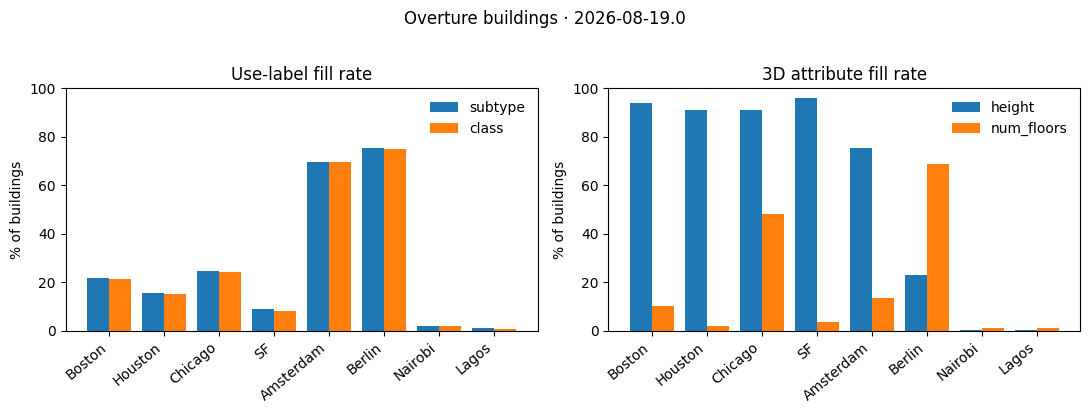

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=False)

cities = list(fill.index)
x = np.arange(len(cities))

axes[0].bar(x - 0.2, fill["pct_subtype"], width=0.4, label="subtype")
axes[0].bar(x + 0.2, fill["pct_class"], width=0.4, label="class")
axes[0].set_xticks(x)
axes[0].set_xticklabels(cities, rotation=40, ha="right")
axes[0].set_ylabel("% of buildings")
axes[0].set_title("Use-label fill rate")
axes[0].legend(frameon=False)
axes[0].set_ylim(0, 100)

axes[1].bar(x - 0.2, fill["pct_height"], width=0.4, label="height")
axes[1].bar(x + 0.2, fill["pct_floors"], width=0.4, label="num_floors")
axes[1].set_xticks(x)
axes[1].set_xticklabels(cities, rotation=40, ha="right")
axes[1].set_ylabel("% of buildings")
axes[1].set_title("3D attribute fill rate")
axes[1].legend(frameon=False)
axes[1].set_ylim(0, 100)

fig.suptitle(f"Overture buildings · {RELEASE}", y=1.02)
fig.tight_layout()
fig.savefig(OUT / "fill_rates_by_city.png", dpi=150, bbox_inches="tight")
plt.show()


## 3. Subtype distribution (labeled only)

Binary GT rule used in notebook 02: `subtype == residential` → residential; any other non-null subtype → non-residential. Unlabeled rows are **excluded**, never treated as negatives.


% of LABELED buildings by subtype:


city,Amsterdam,Berlin,Boston,Chicago,Houston,Lagos,Nairobi,SF
subtype,,,,,,,,
residential,90.50,76.20,79.60,75.20,83.10,81.80,67.00,66.50
commercial,4.20,8.90,8.90,10.90,6.70,5.80,9.10,13.70
outbuilding,2.10,5.60,1.90,4.50,4.70,3.60,1.50,3.80
industrial,2.00,1.60,0.80,2.10,0.30,4.30,10.90,2.30
education,0.40,2.50,3.80,2.00,1.10,0.40,4.20,3.40
civic,0.10,1.40,1.20,1.30,1.10,0.50,1.70,2.60
religious,0.10,0.50,1.30,1.00,0.90,2.40,2.60,2.70
service,0.40,1.60,0.60,0.80,0.10,0.00,0.00,0.50
transportation,0.10,0.40,0.90,1.30,1.40,0.50,0.50,2.10


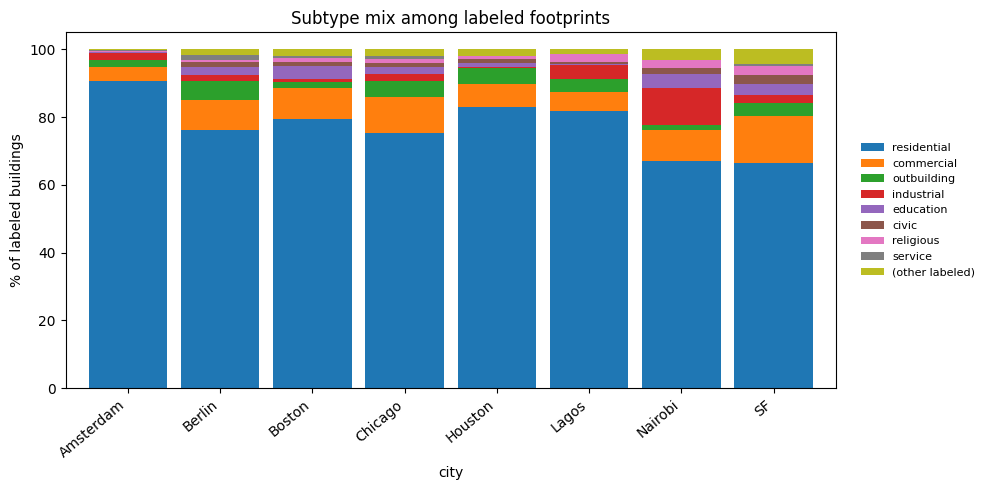

In [7]:
labeled = subtype_df[subtype_df["subtype"] != "(unlabeled)"].copy()
wide = labeled.pivot_table(index="subtype", columns="city", values="n", aggfunc="sum", fill_value=0)
# order by global count
wide = wide.loc[wide.sum(axis=1).sort_values(ascending=False).index]
pct_labeled = wide.div(wide.sum(axis=0), axis=1) * 100

print("% of LABELED buildings by subtype:")
display(pct_labeled.round(1))

fig, ax = plt.subplots(figsize=(10, 5))
# stacked share of top subtypes + other
top = list(wide.sum(axis=1).head(8).index)
stack = wide.reindex(top).fillna(0)
other = wide.drop(index=top, errors="ignore").sum(axis=0)
stack.loc["(other labeled)"] = other
stack_pct = stack.div(stack.sum(axis=0), axis=1) * 100
stack_pct.T.plot(kind="bar", stacked=True, ax=ax, width=0.85)
ax.set_ylabel("% of labeled buildings")
ax.set_title("Subtype mix among labeled footprints")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=8)
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
fig.tight_layout()
fig.savefig(OUT / "subtype_mix_labeled.png", dpi=150, bbox_inches="tight")
plt.show()


## 4. Class distribution + study taxonomy coverage

Count every non-null `class`, then how many map into the 10-way study rollup vs ambiguous / unused.


In [8]:
class_frames = []
study_frames = []
quoted = ", ".join(f"'{c}'" for c in sorted(CLASS_TO_LABEL))

for name, bbox in CITIES.items():
    w = bbox_where(*bbox)
    print(f"Classes · {name} ...", flush=True)
    cdf = con.execute(
        f"SELECT COALESCE(class, '(unlabeled)') AS class, COUNT(*)::BIGINT AS n "
        f"FROM read_parquet('{BUILDINGS}', hive_partitioning=1) WHERE {w} "
        f"GROUP BY 1 ORDER BY n DESC"
    ).df()
    cdf.insert(0, "city", name)
    class_frames.append(cdf)

    sdf = con.execute(
        f"SELECT class, COUNT(*)::BIGINT AS n "
        f"FROM read_parquet('{BUILDINGS}', hive_partitioning=1) "
        f"WHERE {w} AND class IN ({quoted}) "
        f"GROUP BY 1 ORDER BY n DESC"
    ).df()
    sdf.insert(0, "city", name)
    study_frames.append(sdf)

class_df = pd.concat(class_frames, ignore_index=True)
study_df = pd.concat(study_frames, ignore_index=True)
class_df.to_csv(OUT / "buildings_classes_by_city.csv", index=False)
study_df.to_csv(OUT / "study_class_counts.csv", index=False)

# Top classes globally across extracts
top_classes = (
    class_df[class_df["class"] != "(unlabeled)"]
    .groupby("class")["n"]
    .sum()
    .sort_values(ascending=False)
    .head(25)
)
print("Top 25 classes (summed across extracts):")
display(top_classes.to_frame("n"))


Classes · Boston ...
Classes · Houston ...
Classes · Chicago ...
Classes · SF ...
Classes · Amsterdam ...
Classes · Berlin ...
Classes · Nairobi ...
Classes · Lagos ...
Top 25 classes (summed across extracts):


,n
class,
apartments,74248
house,27065
residential,8055
detached,4989
garage,4598
commercial,3936
retail,3675
roof,3024
industrial,3011


In [9]:
# Study rollup coverage
study_df = study_df.copy()
study_df["label"] = study_df["class"].map(CLASS_TO_LABEL)
label_city = (
    study_df.groupby(["city", "label"])["n"]
    .sum()
    .unstack(fill_value=0)
    .reindex(columns=LABEL_ORDER, fill_value=0)
)
label_city.to_csv(OUT / "study_label_counts.csv")
print("High-precision study labels per city:")
display(label_city)

# Ambiguous vs study-mapped vs unlabeled
summary_tax = []
for city in CITIES:
    sub = class_df[class_df["city"] == city]
    n_tot = int(sub["n"].sum())
    n_unlab = int(sub.loc[sub["class"] == "(unlabeled)", "n"].sum())
    labeled_classes = sub[sub["class"] != "(unlabeled)"]
    n_study = int(
        labeled_classes.loc[labeled_classes["class"].isin(CLASS_TO_LABEL), "n"].sum()
    )
    n_ambig = int(
        labeled_classes.loc[~labeled_classes["class"].isin(CLASS_TO_LABEL), "n"].sum()
    )
    summary_tax.append(
        {
            "city": city,
            "n": n_tot,
            "pct_unlabeled_class": 100 * n_unlab / n_tot if n_tot else 0,
            "pct_study_mapped": 100 * n_study / n_tot if n_tot else 0,
            "pct_other_class": 100 * n_ambig / n_tot if n_tot else 0,
            "n_study": n_study,
        }
    )
tax = pd.DataFrame(summary_tax).set_index("city")
tax.to_csv(OUT / "taxonomy_coverage.csv")
tax.round(1)


High-precision study labels per city:


label,single_family,multi_family,retail,hotel,office,industrial,education,medical,religious,civic
city,,,,,,,,,,
Amsterdam,10119,35587,1968,88,111,1081,179,5,57,28
Berlin,1552,20831,1966,182,827,658,878,148,131,381
Boston,7260,9274,1424,58,410,270,856,92,164,79
Chicago,3005,5002,986,122,462,342,310,62,149,82
Houston,9590,384,523,12,94,78,149,9,49,61
Lagos,215,45,61,15,3,61,6,2,8,2
Nairobi,1828,1332,338,37,29,674,225,60,41,15
SF,308,2226,369,37,135,132,143,31,42,38


,n,pct_unlabeled_class,pct_study_mapped,pct_other_class,n_study
city,,,,,
Boston,108701,78.60,18.30,3.10,19887
Houston,91891,84.90,11.90,3.20,10949
Chicago,63123,75.90,16.70,7.40,10522
SF,55489,91.90,6.20,1.90,3461
Amsterdam,75526,30.40,65.20,4.40,49223
Berlin,47315,25.20,58.20,16.60,27554
Nairobi,288829,98.10,1.60,0.30,4579
Lagos,151744,99.10,0.30,0.60,418


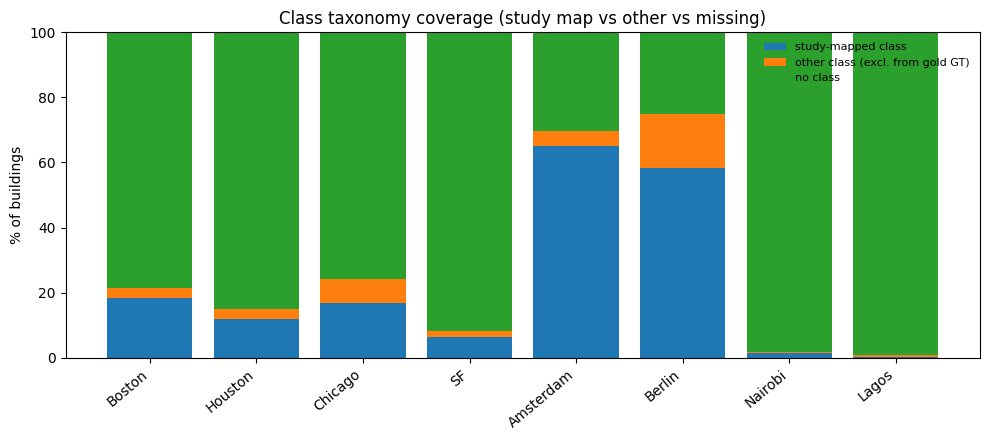

In [10]:
fig, ax = plt.subplots(figsize=(10, 4.5))
x = np.arange(len(tax))
ax.bar(x, tax["pct_study_mapped"], label="study-mapped class")
ax.bar(x, tax["pct_other_class"], bottom=tax["pct_study_mapped"], label="other class (excl. from gold GT)")
ax.bar(
    x,
    tax["pct_unlabeled_class"],
    bottom=tax["pct_study_mapped"] + tax["pct_other_class"],
    label="no class",
)
ax.set_xticks(x)
ax.set_xticklabels(tax.index, rotation=40, ha="right")
ax.set_ylabel("% of buildings")
ax.set_title("Class taxonomy coverage (study map vs other vs missing)")
ax.legend(frameon=False, fontsize=8)
ax.set_ylim(0, 100)
fig.tight_layout()
fig.savefig(OUT / "taxonomy_coverage.png", dpi=150, bbox_inches="tight")
plt.show()


## 5. Sources vs labels

ML footprint providers add area coverage but contribute near-zero `subtype`/`class`. OSM (and some cadastres) carry the labels.


Top 5 sources per city (with subtype fill %):


,city,src,n,n_labeled,pct_labeled
9,Amsterdam,OpenStreetMap,75017,52653,70.19
10,Amsterdam,Microsoft ML Buildings,509,0,0.00
11,Berlin,OpenStreetMap,45317,35609,78.58
12,Berlin,Microsoft ML Buildings,1998,0,0.00
0,Boston,OpenStreetMap,106118,23830,22.46
1,Boston,Microsoft ML Buildings,1445,0,0.00
2,Boston,Esri Community Maps,1138,0,0.00
5,Chicago,OpenStreetMap,62487,15436,24.70
6,Chicago,Microsoft ML Buildings,636,0,0.00
3,Houston,OpenStreetMap,89485,14392,16.08


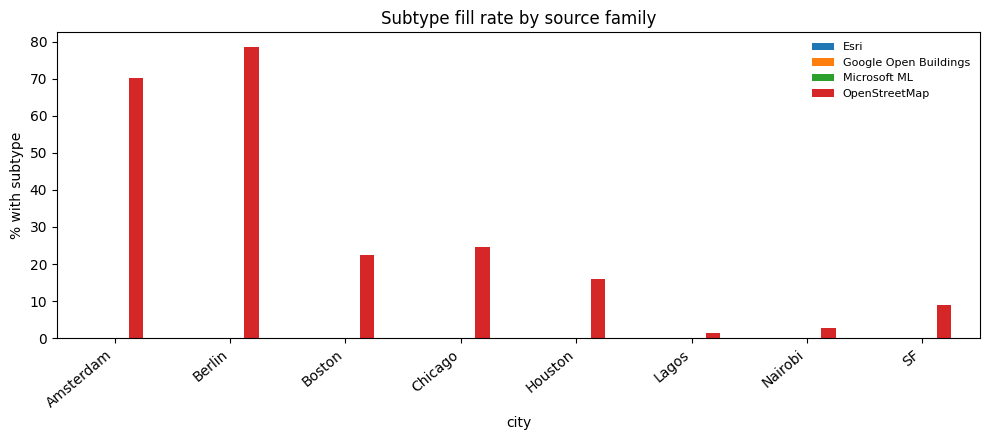

In [11]:
source_df = source_df.copy()
source_df["pct_labeled"] = 100.0 * source_df["n_labeled"] / source_df["n"]

# Top sources per city
top_src = (
    source_df.sort_values(["city", "n"], ascending=[True, False])
    .groupby("city", group_keys=False)
    .head(5)
)
print("Top 5 sources per city (with subtype fill %):")
display(top_src)

fig, ax = plt.subplots(figsize=(10, 4.5))
# Collapse to coarse buckets
def coarse(src: str) -> str:
    s = (src or "").lower()
    if "osm" in s or "openstreetmap" in s:
        return "OpenStreetMap"
    if "microsoft" in s:
        return "Microsoft ML"
    if "google" in s:
        return "Google Open Buildings"
    if "esri" in s:
        return "Esri"
    return "other / unknown"

src2 = source_df.copy()
src2["bucket"] = src2["src"].map(coarse)
bucket = src2.groupby(["city", "bucket"]).agg(n=("n", "sum"), n_labeled=("n_labeled", "sum")).reset_index()
bucket["pct_labeled"] = 100 * bucket["n_labeled"] / bucket["n"]
piv = bucket.pivot_table(index="city", columns="bucket", values="pct_labeled", fill_value=0)
piv.plot(kind="bar", ax=ax)
ax.set_ylabel("% with subtype")
ax.set_title("Subtype fill rate by source family")
ax.legend(frameon=False, fontsize=8)
ax.set_xticklabels(ax.get_xticklabels(), rotation=40, ha="right")
fig.tight_layout()
fig.savefig(OUT / "label_rate_by_source.png", dpi=150, bbox_inches="tight")
plt.show()


## 6. Height & floors (where present)

Sparse 3D priors — useful as optional features, not as primary GT.


In [12]:
height_rows = []
for name, bbox in CITIES.items():
    w = bbox_where(*bbox)
    h = con.execute(
        f"""
        SELECT
          COUNT(height)::BIGINT AS n_h,
          AVG(height) AS mean_h,
          approx_quantile(height, 0.5) AS median_h,
          approx_quantile(height, 0.9) AS p90_h,
          COUNT(num_floors)::BIGINT AS n_f,
          AVG(num_floors) AS mean_f,
          approx_quantile(num_floors, 0.5) AS median_f
        FROM read_parquet('{BUILDINGS}', hive_partitioning=1)
        WHERE {w}
        """
    ).fetchdf().iloc[0].to_dict()
    h["city"] = name
    height_rows.append(h)

height_df = pd.DataFrame(height_rows).set_index("city")
height_df.to_csv(OUT / "height_floors_summary.csv")
height_df.round(2)


,n_h,mean_h,median_h,p90_h,n_f,mean_f,median_f
city,,,,,,,
Boston,102140.00,9.41,8.72,13.91,11181.00,3.61,3.00
Houston,83665.00,6.43,5.37,11.11,1610.00,3.95,2.00
Chicago,57558.00,9.24,7.79,13.54,30283.00,2.95,2.00
SF,53269.00,10.17,9.00,13.15,1904.00,5.96,3.00
Amsterdam,56819.00,13.75,14.86,18.28,10058.00,3.76,4.00
Berlin,10959.00,8.41,4.50,19.27,32481.00,4.37,5.00
Nairobi,275.00,17.29,9.00,29.75,2802.00,6.96,4.00
Lagos,341.00,16.30,9.84,40.00,1768.00,2.87,3.00


## 7. Places (POI) features — noisy GT complement

Places often have denser school/hospital points than building `class` tags. Useful for weak labels via spatial join; expect campus / mixed-use collisions.

| Field | Role |
|---|---|
| `id`, `geometry`, `bbox` | Identity + location |
| `names` | Display name |
| `categories` / `basic_category` / `taxonomy` | POI type hierarchy |
| `confidence` | Source confidence |
| `addresses`, `phones`, `websites`, `emails`, `socials` | Contact |
| `brand`, `operating_status` | Brand / open-closed |
| `sources` | Provenance |


In [13]:
place_schema = con.execute(
    f"DESCRIBE SELECT * FROM read_parquet('{PLACES}', hive_partitioning=1) LIMIT 0"
).df()[["column_name", "column_type"]]
place_schema.to_csv(OUT / "places_schema.csv", index=False)
place_schema


,column_name,column_type
0,id,VARCHAR
1,geometry,GEOMETRY('OGC:CRS84')
2,categories,"STRUCT(""primary"" VARCHAR, alternate VARCHAR[])"
3,confidence,DOUBLE
4,websites,VARCHAR[]
5,emails,VARCHAR[]
6,socials,VARCHAR[]
7,phones,VARCHAR[]
8,brand,"STRUCT(wikidata VARCHAR, ""names"" STRUCT(""primary"" VARCHAR, common MAP(VARCHAR, VARCHAR), rules S..."
9,addresses,"STRUCT(freeform VARCHAR, locality VARCHAR, postcode VARCHAR, region VARCHAR, country VARCHAR)[]"


In [14]:
place_rows = []
for name, (xmin, ymin, xmax, ymax) in CITIES.items():
    # Places often use BETWEEN-style bbox filters in notebook 01
    w = (
        f"bbox.xmin BETWEEN {xmin} AND {xmax} "
        f"AND bbox.ymin BETWEEN {ymin} AND {ymax}"
    )
    print(f"Places · {name} ...", flush=True)
    inst = con.execute(
        f"""
        SELECT
          COUNT(*)::BIGINT AS n_places,
          COUNT(categories.primary)::BIGINT AS n_cat_primary,
          COUNT(basic_category)::BIGINT AS n_basic_cat,
          COUNT(taxonomy.primary)::BIGINT AS n_tax_primary,
          COUNT(names.primary)::BIGINT AS n_names,
          COUNT(confidence)::BIGINT AS n_confidence,
          SUM(CASE WHEN taxonomy.hierarchy[1] = 'education' THEN 1 ELSE 0 END)::BIGINT AS education_l0,
          SUM(CASE WHEN taxonomy.hierarchy[1] = 'health_care' THEN 1 ELSE 0 END)::BIGINT AS health_l0,
          SUM(CASE WHEN basic_category IN (
                'school','elementary_school','high_school','middle_school','preschool'
              ) OR taxonomy.primary IN (
                'school','elementary_school','high_school','middle_school'
              ) THEN 1 ELSE 0 END)::BIGINT AS school_pois,
          SUM(CASE WHEN basic_category IN ('hospital','medical_center')
              OR taxonomy.primary IN ('hospital','medical_center')
              THEN 1 ELSE 0 END)::BIGINT AS hospital_pois
        FROM read_parquet('{PLACES}', hive_partitioning=1)
        WHERE {w}
        """
    ).fetchone()
    place_rows.append(
        {
            "city": name,
            "n_places": inst[0],
            "pct_cat_primary": 100 * inst[1] / inst[0] if inst[0] else 0,
            "pct_basic_cat": 100 * inst[2] / inst[0] if inst[0] else 0,
            "pct_tax_primary": 100 * inst[3] / inst[0] if inst[0] else 0,
            "pct_names": 100 * inst[4] / inst[0] if inst[0] else 0,
            "education_l0": inst[6],
            "health_l0": inst[7],
            "school_pois": inst[8],
            "hospital_pois": inst[9],
        }
    )

places_df = pd.DataFrame(place_rows).set_index("city")
places_df.to_csv(OUT / "places_fill_and_institutions.csv")
places_df.round(1)


Places · Boston ...
Places · Houston ...
Places · Chicago ...
Places · SF ...
Places · Amsterdam ...
Places · Berlin ...
Places · Nairobi ...
Places · Lagos ...


,n_places,pct_cat_primary,pct_basic_cat,pct_tax_primary,pct_names,education_l0,health_l0,school_pois,hospital_pois
city,,,,,,,,,
Boston,48986,95.20,96.50,95.20,100.00,2550,7280,502,399
Houston,47701,57.60,58.30,57.60,100.00,809,2856,213,48
Chicago,61607,76.60,77.70,76.60,100.00,1602,6611,322,223
SF,45220,95.70,97.10,95.70,100.00,1185,6186,299,102
Amsterdam,27112,96.40,97.50,96.40,100.00,990,1014,295,29
Berlin,49000,95.30,96.00,95.30,100.00,2016,2440,540,99
Nairobi,36722,95.00,95.30,95.00,100.00,1666,1197,677,363
Lagos,14436,91.90,92.00,91.90,100.00,1017,338,447,95


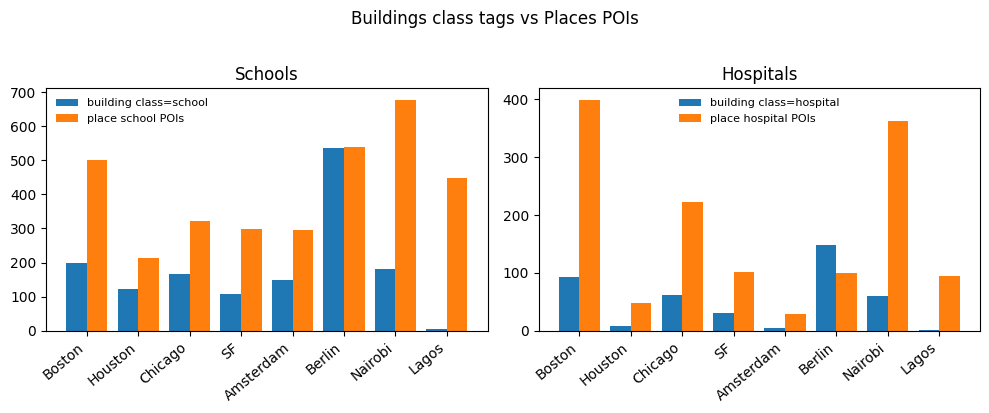

,school_pois,hospital_pois,school_buildings,hospital_buildings
city,,,,
Boston,502,399,199,92
Houston,213,48,123,9
Chicago,322,223,165,62
SF,299,102,109,31
Amsterdam,295,29,149,5
Berlin,540,99,536,148
Nairobi,677,363,182,60
Lagos,447,95,5,2


In [15]:
# Compare building class=school/hospital vs Places POIs
compare = places_df[["school_pois", "hospital_pois"]].copy()
school_b = []
hosp_b = []
for city in compare.index:
    sub = study_df[study_df["city"] == city]
    school_b.append(int(sub.loc[sub["class"] == "school", "n"].sum()))
    hosp_b.append(int(sub.loc[sub["class"] == "hospital", "n"].sum()))
compare["school_buildings"] = school_b
compare["hospital_buildings"] = hosp_b
compare.to_csv(OUT / "buildings_vs_places_institutions.csv")

fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharey=False)
cities = list(compare.index)
x = np.arange(len(cities))
axes[0].bar(x - 0.2, compare["school_buildings"], width=0.4, label="building class=school")
axes[0].bar(x + 0.2, compare["school_pois"], width=0.4, label="place school POIs")
axes[0].set_xticks(x)
axes[0].set_xticklabels(cities, rotation=40, ha="right")
axes[0].set_title("Schools")
axes[0].legend(frameon=False, fontsize=8)

axes[1].bar(x - 0.2, compare["hospital_buildings"], width=0.4, label="building class=hospital")
axes[1].bar(x + 0.2, compare["hospital_pois"], width=0.4, label="place hospital POIs")
axes[1].set_xticks(x)
axes[1].set_xticklabels(cities, rotation=40, ha="right")
axes[1].set_title("Hospitals")
axes[1].legend(frameon=False, fontsize=8)

fig.suptitle("Buildings class tags vs Places POIs", y=1.02)
fig.tight_layout()
fig.savefig(OUT / "buildings_vs_places.png", dpi=150, bbox_inches="tight")
plt.show()
compare


## 8. US region → state → city analysis

Compare Overture **use-label fill** and study-taxonomy coverage across a US hierarchy:

| Level | Definition |
|---|---|
| **Region** | U.S. Census Bureau regions (Northeast, Midwest, South, West) |
| **State** | State containing each city AOI |
| **City** | Compact downtown / near-downtown bbox (same style as notebooks 02–05) |

**Method.** Query cheap **downtown** extracts, then **roll up** counts to state and region (weighted by building count). These AOIs are not full cities or states — they are comparable urban cores.

**This is a 15-downtown sample.** Section 8b repeats the same rollup using every Census place in the USA.

**Fill rate** = % of buildings with a non-null attribute (e.g. `subtype`).


In [16]:
# US hierarchy: Census region → state → city (compact AOIs)
# bbox = (xmin, ymin, xmax, ymax)
US_HIERARCHY = [
    # Northeast
    {"region": "Northeast", "state": "MA", "city": "Boston", "bbox": (-71.20, 42.28, -70.95, 42.42)},
    {"region": "Northeast", "state": "NY", "city": "NYC", "bbox": (-74.05, 40.68, -73.90, 40.82)},
    {"region": "Northeast", "state": "PA", "city": "Philadelphia", "bbox": (-75.20, 39.92, -75.10, 40.00)},
    # Midwest
    {"region": "Midwest", "state": "IL", "city": "Chicago", "bbox": (-87.75, 41.80, -87.55, 41.95)},
    {"region": "Midwest", "state": "OH", "city": "Columbus", "bbox": (-83.05, 39.94, -82.95, 40.02)},
    {"region": "Midwest", "state": "MN", "city": "Minneapolis", "bbox": (-93.30, 44.95, -93.20, 45.02)},
    # South
    {"region": "South", "state": "TX", "city": "Houston", "bbox": (-95.50, 29.70, -95.25, 29.85)},
    {"region": "South", "state": "GA", "city": "Atlanta", "bbox": (-84.45, 33.70, -84.30, 33.85)},
    {"region": "South", "state": "FL", "city": "Miami", "bbox": (-80.30, 25.74, -80.18, 25.85)},
    {"region": "South", "state": "NC", "city": "Charlotte", "bbox": (-80.90, 35.18, -80.78, 35.28)},
    # West
    {"region": "West", "state": "CA", "city": "SF", "bbox": (-122.45, 37.74, -122.38, 37.81)},
    {"region": "West", "state": "CA", "city": "LA", "bbox": (-118.35, 34.00, -118.20, 34.12)},
    {"region": "West", "state": "WA", "city": "Seattle", "bbox": (-122.40, 47.55, -122.25, 47.68)},
    {"region": "West", "state": "CO", "city": "Denver", "bbox": (-105.05, 39.68, -104.90, 39.80)},
    {"region": "West", "state": "AZ", "city": "Phoenix", "bbox": (-112.15, 33.40, -111.95, 33.55)},
]

us_meta = pd.DataFrame(US_HIERARCHY)
print(us_meta.groupby(["region", "state"]).size().rename("n_cities").to_string())
print(f"\n{len(us_meta)} city AOIs across {us_meta['state'].nunique()} states / {us_meta['region'].nunique()} regions")
us_meta


region     state
Midwest    IL       1
           MN       1
           OH       1
Northeast  MA       1
           NY       1
           PA       1
South      FL       1
           GA       1
           NC       1
           TX       1
West       AZ       1
           CA       2
           CO       1
           WA       1

15 city AOIs across 14 states / 4 regions


,region,state,city,bbox
0,Northeast,MA,Boston,"(-71.2, 42.28, -70.95, 42.42)"
1,Northeast,NY,NYC,"(-74.05, 40.68, -73.9, 40.82)"
2,Northeast,PA,Philadelphia,"(-75.2, 39.92, -75.1, 40.0)"
3,Midwest,IL,Chicago,"(-87.75, 41.8, -87.55, 41.95)"
4,Midwest,OH,Columbus,"(-83.05, 39.94, -82.95, 40.02)"
5,Midwest,MN,Minneapolis,"(-93.3, 44.95, -93.2, 45.02)"
6,South,TX,Houston,"(-95.5, 29.7, -95.25, 29.85)"
7,South,GA,Atlanta,"(-84.45, 33.7, -84.3, 33.85)"
8,South,FL,Miami,"(-80.3, 25.74, -80.18, 25.85)"
9,South,NC,Charlotte,"(-80.9, 35.18, -80.78, 35.28)"


In [17]:
# City-level building stats for the US hierarchy
us_city_rows = []
us_subtype_frames = []
us_study_frames = []
quoted_classes = ", ".join(f"'{c}'" for c in sorted(CLASS_TO_LABEL))

for rec in US_HIERARCHY:
    name = rec["city"]
    w = bbox_where(*rec["bbox"])
    print(f"US city · {rec['region']} / {rec['state']} / {name} ...", flush=True)

    row = con.execute(
        f"""
        SELECT
          COUNT(*)::BIGINT AS n,
          COUNT(subtype)::BIGINT AS n_subtype,
          COUNT(class)::BIGINT AS n_class,
          COUNT(height)::BIGINT AS n_height,
          COUNT(num_floors)::BIGINT AS n_floors,
          SUM(CASE WHEN subtype = 'residential' THEN 1 ELSE 0 END)::BIGINT AS n_res,
          SUM(CASE WHEN subtype IS NOT NULL AND subtype != 'residential' THEN 1 ELSE 0 END)::BIGINT AS n_nonres,
          SUM(CASE WHEN class IN ({quoted_classes}) THEN 1 ELSE 0 END)::BIGINT AS n_study
        FROM read_parquet('{BUILDINGS}', hive_partitioning=1)
        WHERE {w}
        """
    ).fetchdf().iloc[0].to_dict()

    row.update(
        {
            "region": rec["region"],
            "state": rec["state"],
            "city": name,
            "xmin": rec["bbox"][0],
            "ymin": rec["bbox"][1],
            "xmax": rec["bbox"][2],
            "ymax": rec["bbox"][3],
        }
    )
    us_city_rows.append(row)

    st = con.execute(
        f"""
        SELECT COALESCE(subtype, '(unlabeled)') AS subtype, COUNT(*)::BIGINT AS n
        FROM read_parquet('{BUILDINGS}', hive_partitioning=1)
        WHERE {w}
        GROUP BY 1
        """
    ).df()
    st.insert(0, "city", name)
    st.insert(0, "state", rec["state"])
    st.insert(0, "region", rec["region"])
    us_subtype_frames.append(st)

    sd = con.execute(
        f"""
        SELECT class, COUNT(*)::BIGINT AS n
        FROM read_parquet('{BUILDINGS}', hive_partitioning=1)
        WHERE {w} AND class IN ({quoted_classes})
        GROUP BY 1
        """
    ).df()
    if len(sd):
        sd.insert(0, "city", name)
        sd.insert(0, "state", rec["state"])
        sd.insert(0, "region", rec["region"])
        us_study_frames.append(sd)

us_city = pd.DataFrame(us_city_rows)
for col, base in [
    ("pct_subtype", "n_subtype"),
    ("pct_class", "n_class"),
    ("pct_height", "n_height"),
    ("pct_floors", "n_floors"),
    ("pct_study", "n_study"),
]:
    us_city[col] = 100.0 * us_city[base] / us_city["n"].clip(lower=1)

us_city["pct_res_of_labeled"] = 100.0 * us_city["n_res"] / (us_city["n_res"] + us_city["n_nonres"]).clip(lower=1)

us_subtype = pd.concat(us_subtype_frames, ignore_index=True)
us_study = pd.concat(us_study_frames, ignore_index=True) if us_study_frames else pd.DataFrame()

us_city.to_csv(OUT / "us_city_fill_rates.csv", index=False)
us_subtype.to_csv(OUT / "us_subtypes_by_city.csv", index=False)
us_study.to_csv(OUT / "us_study_classes_by_city.csv", index=False)

cols = [
    "region", "state", "city", "n",
    "pct_subtype", "pct_class", "pct_study", "pct_height",
    "pct_res_of_labeled",
]
us_city[cols].sort_values(["region", "state", "city"]).round(1)


US city · Northeast / MA / Boston ...
US city · Northeast / NY / NYC ...
US city · Northeast / PA / Philadelphia ...
US city · Midwest / IL / Chicago ...
US city · Midwest / OH / Columbus ...
US city · Midwest / MN / Minneapolis ...
US city · South / TX / Houston ...
US city · South / GA / Atlanta ...
US city · South / FL / Miami ...
US city · South / NC / Charlotte ...
US city · West / CA / SF ...
US city · West / CA / LA ...
US city · West / WA / Seattle ...
US city · West / CO / Denver ...
US city · West / AZ / Phoenix ...


,region,state,city,n,pct_subtype,pct_class,pct_study,pct_height,pct_res_of_labeled
3,Midwest,IL,Chicago,248547,12.40,12.20,6.90,91.70,76.50
5,Midwest,MN,Minneapolis,44861,50.60,49.80,25.60,65.60,89.40
4,Midwest,OH,Columbus,60187,51.80,51.50,26.20,92.30,88.00
0,Northeast,MA,Boston,205813,13.80,13.40,10.80,91.90,77.70
1,Northeast,NY,NYC,185831,14.80,14.20,11.70,97.90,79.50
2,Northeast,PA,Philadelphia,158857,5.80,5.30,3.70,98.10,75.60
8,South,FL,Miami,101146,8.30,8.10,7.20,98.50,82.40
7,South,GA,Atlanta,118893,59.00,58.30,56.60,79.30,94.20
9,South,NC,Charlotte,57928,26.00,25.10,20.20,68.50,82.40
6,South,TX,Houston,236974,12.50,12.10,9.60,91.40,79.40


In [18]:
def rollup_geo(df: pd.DataFrame, group_cols: list[str]) -> pd.DataFrame:
    """Count-weighted rollup of fill rates to state or region."""
    g = df.groupby(group_cols, as_index=False).agg(
        n_cities=("city", "nunique"),
        n=("n", "sum"),
        n_subtype=("n_subtype", "sum"),
        n_class=("n_class", "sum"),
        n_height=("n_height", "sum"),
        n_floors=("n_floors", "sum"),
        n_res=("n_res", "sum"),
        n_nonres=("n_nonres", "sum"),
        n_study=("n_study", "sum"),
    )
    for col, base in [
        ("pct_subtype", "n_subtype"),
        ("pct_class", "n_class"),
        ("pct_height", "n_height"),
        ("pct_floors", "n_floors"),
        ("pct_study", "n_study"),
    ]:
        g[col] = 100.0 * g[base] / g["n"].clip(lower=1)
    g["pct_res_of_labeled"] = 100.0 * g["n_res"] / (g["n_res"] + g["n_nonres"]).clip(lower=1)
    return g


us_state = rollup_geo(us_city, ["region", "state"])
us_region = rollup_geo(us_city, ["region"])

us_state.to_csv(OUT / "us_state_fill_rates.csv", index=False)
us_region.to_csv(OUT / "us_region_fill_rates.csv", index=False)

print("=== Region ===")
display(us_region[["region", "n_cities", "n", "pct_subtype", "pct_class", "pct_study", "pct_height", "pct_res_of_labeled"]].round(1))
print("=== State ===")
display(us_state[["region", "state", "n_cities", "n", "pct_subtype", "pct_class", "pct_study", "pct_height", "pct_res_of_labeled"]].round(1))


=== Region ===


,region,n_cities,n,pct_subtype,pct_class,pct_study,pct_height,pct_res_of_labeled
0,Midwest,3,353595,24.00,23.70,12.60,88.50,84.20
1,Northeast,3,550501,11.80,11.30,9.10,95.70,78.20
2,South,4,514941,23.90,23.50,21.20,87.40,88.40
3,West,5,761654,62.70,62.30,44.70,89.30,86.70


=== State ===


,region,state,n_cities,n,pct_subtype,pct_class,pct_study,pct_height,pct_res_of_labeled
0,Midwest,IL,1,248547,12.40,12.20,6.90,91.70,76.50
1,Midwest,MN,1,44861,50.60,49.80,25.60,65.60,89.40
2,Midwest,OH,1,60187,51.80,51.50,26.20,92.30,88.00
3,Northeast,MA,1,205813,13.80,13.40,10.80,91.90,77.70
4,Northeast,NY,1,185831,14.80,14.20,11.70,97.90,79.50
5,Northeast,PA,1,158857,5.80,5.30,3.70,98.10,75.60
6,South,FL,1,101146,8.30,8.10,7.20,98.50,82.40
7,South,GA,1,118893,59.00,58.30,56.60,79.30,94.20
8,South,NC,1,57928,26.00,25.10,20.20,68.50,82.40
9,South,TX,1,236974,12.50,12.10,9.60,91.40,79.40


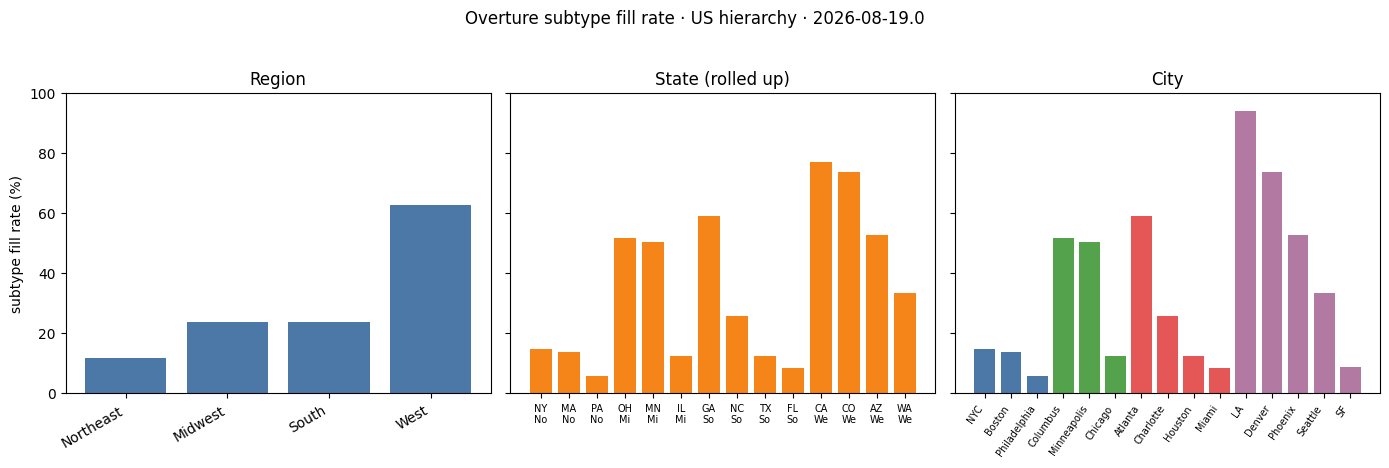

In [19]:
# Side-by-side fill-rate comparison at region / state / city
REGION_ORDER = ["Northeast", "Midwest", "South", "West"]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.5), sharey=True)

# Region
r = us_region.set_index("region").reindex(REGION_ORDER)
axes[0].bar(np.arange(len(r)), r["pct_subtype"], color="#4C78A8")
axes[0].set_xticks(np.arange(len(r)))
axes[0].set_xticklabels(r.index, rotation=30, ha="right")
axes[0].set_title("Region")
axes[0].set_ylabel("subtype fill rate (%)")
axes[0].set_ylim(0, 100)

# State (sorted within region)
s = us_state.copy()
s["region"] = pd.Categorical(s["region"], REGION_ORDER, ordered=True)
s = s.sort_values(["region", "pct_subtype"], ascending=[True, False])
axes[1].bar(np.arange(len(s)), s["pct_subtype"], color="#F58518")
axes[1].set_xticks(np.arange(len(s)))
axes[1].set_xticklabels(s["state"] + "\n" + s["region"].astype(str).str[:2], fontsize=7)
axes[1].set_title("State (rolled up)")

# City
c = us_city.copy()
c["region"] = pd.Categorical(c["region"], REGION_ORDER, ordered=True)
c = c.sort_values(["region", "pct_subtype"], ascending=[True, False])
colors = c["region"].map(
    {"Northeast": "#4C78A8", "Midwest": "#54A24B", "South": "#E45756", "West": "#B279A2"}
)
axes[2].bar(np.arange(len(c)), c["pct_subtype"], color=colors)
axes[2].set_xticks(np.arange(len(c)))
axes[2].set_xticklabels(c["city"], rotation=55, ha="right", fontsize=7)
axes[2].set_title("City")

fig.suptitle(f"Overture subtype fill rate · US hierarchy · {RELEASE}", y=1.03)
fig.tight_layout()
fig.savefig(OUT / "us_fill_rate_region_state_city.png", dpi=150, bbox_inches="tight")
plt.show()


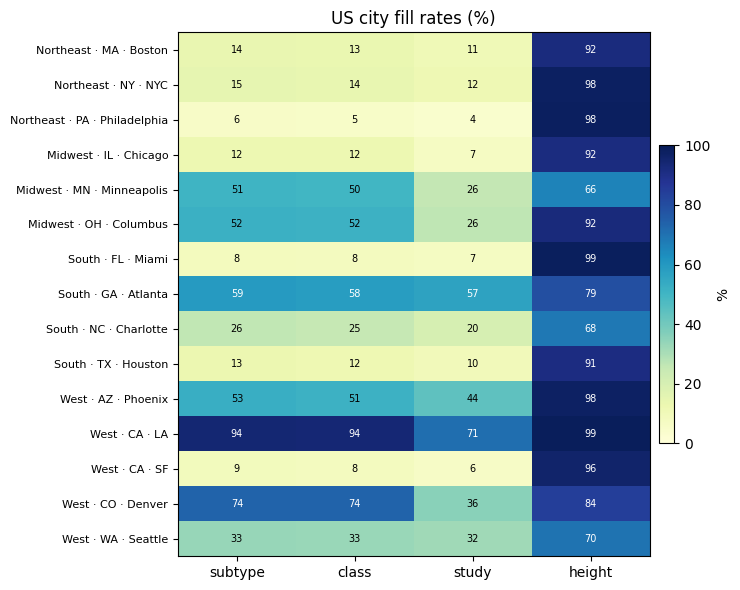

pct_subtype  pct_class  pct_study  pct_height
region    state city                                                       
Northeast MA    Boston              13.80      13.40      10.80       91.90
          NY    NYC                 14.80      14.20      11.70       97.90
          PA    Philadelphia         5.80       5.30       3.70       98.10
Midwest   IL    Chicago             12.40      12.20       6.90       91.70
          MN    Minneapolis         50.60      49.80      25.60       65.60
          OH    Columbus            51.80      51.50      26.20       92.30
South     FL    Miami                8.30       8.10       7.20       98.50
          GA    Atlanta             59.00      58.30      56.60       79.30
          NC    Charlotte           26.00      25.10      20.20       68.50
          TX    Houston             12.50      12.10       9.60       91.40
West      AZ    Phoenix             52.60      51.40      43.90       97.60
          CA    LA                  94.20      94.00      71.10       99.20
                SF                   8.80       8.10       6.20       96.00
          CO    Denver              73.60      73.50      35.60       84.20
          WA    Seattle             33.50      33.10      31.70       69.80

In [20]:
# Heatmap-style table: fill rates by city
metric_cols = ["pct_subtype", "pct_class", "pct_study", "pct_height"]
heat = (
    us_city.assign(
        region=pd.Categorical(us_city["region"], REGION_ORDER, ordered=True)
    )
    .sort_values(["region", "state", "city"])
    .set_index(["region", "state", "city"])[metric_cols]
)

fig, ax = plt.subplots(figsize=(7.5, 6))
im = ax.imshow(heat.values, aspect="auto", cmap="YlGnBu", vmin=0, vmax=100)
ax.set_xticks(range(len(metric_cols)))
ax.set_xticklabels([c.replace("pct_", "") for c in metric_cols])
ax.set_yticks(range(len(heat)))
ax.set_yticklabels([f"{r} · {s} · {c}" for r, s, c in heat.index], fontsize=8)
for i in range(heat.shape[0]):
    for j in range(heat.shape[1]):
        v = heat.values[i, j]
        ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=7,
                color="white" if v > 55 else "black")
ax.set_title("US city fill rates (%)")
fig.colorbar(im, ax=ax, fraction=0.03, pad=0.02, label="%")
fig.tight_layout()
fig.savefig(OUT / "us_city_fill_heatmap.png", dpi=150, bbox_inches="tight")
plt.show()
heat.round(1)


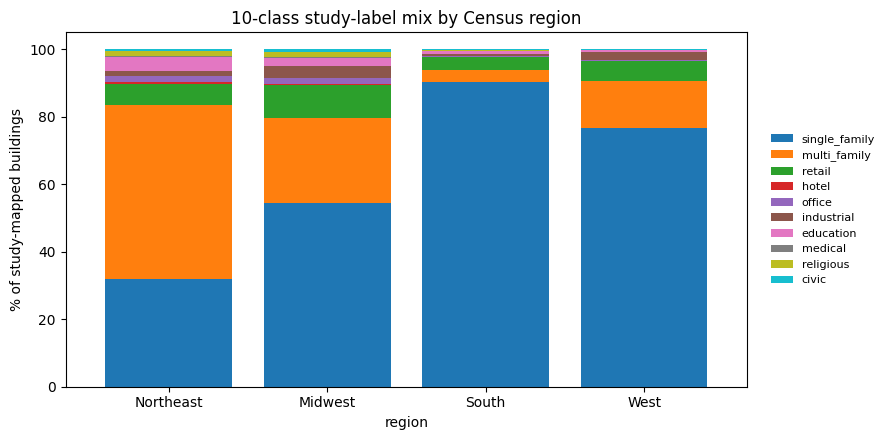

Study-mapped counts by region:


label,single_family,multi_family,retail,hotel,office,industrial,education,medical,religious,civic
region,,,,,,,,,,
Midwest,24200,11291,4345,162,687,1599,1108,141,647,358
Northeast,15853,25714,3223,295,795,715,2100,240,696,250
South,98403,3984,3984,106,458,584,920,120,284,139
West,260508,48288,19580,511,588,7788,1965,371,510,355



Study-mapped counts by state:


label            single_family  multi_family  retail  hotel  office  \
region    state                                                       
Midwest   IL              5355          6726    2173    133     504   
          MN              8531          1484     609     16     127   
          OH             10314          3081    1563     13      56   
Northeast MA              8533          9823    1731     64     459   
          NY              3662         14873     918    223     302   
          PA              3658          1018     574      8      34   
South     FL              6241           311     530     15      18   
          GA             63693          1175    1640     36     113   
          NC              9864           976     435      6     122   
          TX             18605          1522    1379     49     205   
West      AZ             60882          3214    2497     55     101   
          CA            101387         40210   11290    398     171   
          CO             54954          2411    4976     35      98   
          WA             43285          2453     817     23     218   

label            industrial  education  medical  religious  civic  
region    state                                                    
Midwest   IL            953        687       79        451    208  
          MN            467        177       27         48     14  
          OH            179        244       35        148    136  
Northeast MA            313        986       96        197     99  
          NY            293        813       84        364    126  
          PA            109        301       60        135     25  
South     FL             33         93       16         16     17  
          GA             84        374       34         73     26  
          NC             65        133       14         86      6  
          TX            402        320       56        109     90  
West      AZ            306        385       60        194     48  
          CA           6077       1016      217         99     62  
          CO           1232        264       37        149    222  
          WA            173        300       57         68     23

In [21]:
# Study-label mix rolled up to region (and state)
if len(us_study):
    us_study = us_study.copy()
    us_study["label"] = us_study["class"].map(CLASS_TO_LABEL)

    def label_mix(group_cols):
        g = us_study.groupby(group_cols + ["label"])["n"].sum().unstack(fill_value=0)
        g = g.reindex(columns=LABEL_ORDER, fill_value=0)
        return g

    region_labels = label_mix(["region"])
    state_labels = label_mix(["region", "state"])
    city_labels = label_mix(["region", "state", "city"])

    region_labels.to_csv(OUT / "us_region_study_labels.csv")
    state_labels.to_csv(OUT / "us_state_study_labels.csv")
    city_labels.to_csv(OUT / "us_city_study_labels.csv")

    # Region stacked share
    fig, ax = plt.subplots(figsize=(9, 4.5))
    pct = region_labels.div(region_labels.sum(axis=1), axis=0) * 100
    pct = pct.reindex(REGION_ORDER)
    pct.plot(kind="bar", stacked=True, ax=ax, width=0.8)
    ax.set_ylabel("% of study-mapped buildings")
    ax.set_title("10-class study-label mix by Census region")
    ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=8)
    ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
    fig.tight_layout()
    fig.savefig(OUT / "us_region_study_label_mix.png", dpi=150, bbox_inches="tight")
    plt.show()

    print("Study-mapped counts by region:")
    display(region_labels)
    print("\nStudy-mapped counts by state:")
    display(state_labels)
else:
    print("No study-mapped classes found in US extracts.")


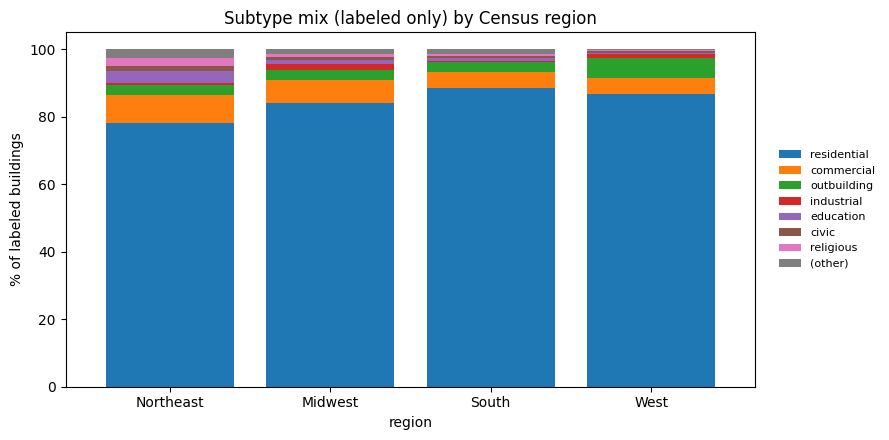

Subtype % of labeled · region:


subtype,agricultural,civic,commercial,education,entertainment,industrial,medical,military,outbuilding,religious,residential,service,transportation
region,,,,,,,,,,,,,
Northeast,0.00,1.40,8.10,3.40,0.70,0.80,0.50,0.00,3.00,2.40,78.20,0.50,0.80
Midwest,0.10,0.90,6.60,1.30,0.20,1.80,0.20,0.00,2.90,0.90,84.20,0.30,0.50
South,0.00,0.50,4.80,0.80,0.20,0.30,0.20,0.00,3.10,0.80,88.40,0.10,0.80
West,0.00,0.50,4.90,0.40,0.10,1.20,0.10,0.00,5.70,0.20,86.70,0.00,0.10



Subtype % of labeled · state:


subtype          agricultural  civic  commercial  education  entertainment  \
region    state                                                              
Midwest   IL             0.10   1.30        9.90       2.30           0.20   
          MN             0.00   0.60        3.80       0.80           0.20   
          OH             0.10   0.70        5.50       0.80           0.10   
Northeast MA             0.10   1.30        9.10       3.70           0.50   
          NY             0.00   1.50        6.60       3.10           0.70   
          PA             0.00   1.30        9.70       3.60           1.10   
South     FL             0.00   1.10        8.40       1.20           0.40   
          GA             0.00   0.20        3.00       0.60           0.10   
          NC             0.00   0.80        5.40       0.90           0.40   
          TX             0.10   0.90        7.60       1.10           0.30   
West      AZ             0.00   1.80        3.60       0.50           0.10   
          CA             0.00   0.10        6.70       0.50           0.10   
          CO             0.00   0.30        3.90       0.20           0.00   
          WA             0.00   0.40        2.60       0.60           0.10   

subtype          industrial  medical  military  outbuilding  religious  \
region    state                                                          
Midwest   IL           2.90     0.30      0.00         3.50       1.60   
          MN           2.00     0.20      0.00         1.90       0.50   
          OH           0.50     0.10      0.00         3.00       0.60   
Northeast MA           0.80     0.50      0.00         3.50       1.40   
          NY           0.70     0.50      0.00         3.10       2.90   
          PA           1.10     0.80      0.00         1.10       4.10   
South     FL           0.20     0.30      0.00         3.50       0.50   
          GA           0.10     0.10      0.00         0.60       0.60   
          NC           0.20     0.30      0.00         7.10       1.20   
          TX           1.10     0.30      0.00         6.70       0.90   
West      AZ           0.30     0.10      0.00        10.80       0.40   
          CA           2.00     0.10      0.00         0.30       0.10   
          CO           0.90     0.00      0.00        13.10       0.10   
          WA           0.30     0.20      0.00         1.00       0.40   

subtype          residential  service  transportation  
region    state                                        
Midwest   IL           76.50     0.50            0.90  
          MN           89.40     0.10            0.40  
          OH           88.00     0.20            0.30  
Northeast MA           77.70     0.60            0.80  
          NY           79.50     0.60            0.70  
          PA           75.60     0.20            1.30  
South     FL           82.40     0.20            1.70  
          GA           94.20     0.10            0.50  
          NC           82.40     0.10            1.20  
          TX           79.40     0.30            1.30  
West      AZ           82.20     0.00            0.20  
          CA           90.00     0.00            0.10  
          CO           81.30     0.00            0.10  
          WA           94.00     0.20            0.20

In [22]:
# Subtype mix among LABELED buildings by region / state
lab = us_subtype[us_subtype["subtype"] != "(unlabeled)"].copy()

region_sub = lab.groupby(["region", "subtype"])["n"].sum().unstack(fill_value=0)
region_sub_pct = region_sub.div(region_sub.sum(axis=1), axis=0) * 100
region_sub_pct = region_sub_pct.reindex(REGION_ORDER)

state_sub = lab.groupby(["region", "state", "subtype"])["n"].sum().unstack(fill_value=0)
state_sub_pct = state_sub.div(state_sub.sum(axis=1), axis=0) * 100

region_sub_pct.to_csv(OUT / "us_region_subtype_mix_pct.csv")
state_sub_pct.to_csv(OUT / "us_state_subtype_mix_pct.csv")

fig, ax = plt.subplots(figsize=(9, 4.5))
# keep top subtypes + other
top_st = region_sub.sum(axis=0).sort_values(ascending=False).head(7).index.tolist()
stack = region_sub[top_st].copy()
stack["(other)"] = region_sub.drop(columns=top_st, errors="ignore").sum(axis=1)
stack_pct = stack.div(stack.sum(axis=1), axis=0) * 100
stack_pct = stack_pct.reindex(REGION_ORDER)
stack_pct.plot(kind="bar", stacked=True, ax=ax, width=0.8)
ax.set_ylabel("% of labeled buildings")
ax.set_title("Subtype mix (labeled only) by Census region")
ax.legend(loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False, fontsize=8)
ax.set_xticklabels(ax.get_xticklabels(), rotation=0)
fig.tight_layout()
fig.savefig(OUT / "us_region_subtype_mix.png", dpi=150, bbox_inches="tight")
plt.show()

print("Subtype % of labeled · region:")
display(region_sub_pct.round(1))
print("\nSubtype % of labeled · state:")
display(state_sub_pct.round(1))


### US hierarchy read-out

| Question | What to look at |
|---|---|
| Where is clean binary GT densest? | `pct_subtype` at city → rolled to state/region |
| Where can we train 10-class models? | `pct_study` / study-label tables |
| Does residential dominate labels? | `pct_res_of_labeled` and subtype mix plots |
| Regional generalization risk? | Large gaps in fill rate or class mix across Census regions |

Expect **Northeast / some West cores** to show higher OSM use-label fill than many **South / Sun Belt** extracts — consistent with Phase 1 findings (Boston ~20% vs Houston ~15% subtype fill in small cores; Europe much higher).

The region/state numbers above are **only these 15 downtowns**. Section 8b uses every Census place in the 50 states + DC.


## 8b. Every US city — then roll up to state and region

Section 8 used **15 downtown boxes**. Those region and state percents are not the country.

This section assigns every Overture building whose centroid falls inside a **Census place** polygon (city, town, village, or CDP) in the 50 states + DC. Then we roll those places up to state and Census region — same counts as section 8, now over the full city list.

| | 15 downtowns (section 8) | This section |
|---|---|---|
| Boundary | Compact bbox | Full Census place polygon |
| How many places | 15 | All Census places (~32k) |
| Buildings outside a city | Not in the sample | Left out (unincorporated) |
| State number | One downtown (CA = SF + LA) | Every place in that state |

We use Census places, not Overture `locality`. Overture locality misses consolidated city-counties (San Francisco, Denver).

The S3 scan is state-by-state and writes checkpoints under `outputs/overture_eda/us_all_cities_by_state/`. Re-run with `FORCE_REBUILD = True` to replace them.

**Do not start this cell while `scripts/overture_us_all_cities.py` is already running** — the two jobs would write the same checkpoint files.


In [23]:
# Nationwide extract: every Census place in the 50 states + DC.
# First run takes a long time (S3 scan per state). Later runs reuse checkpoints.
FORCE_REBUILD = False
STATES = None  # e.g. ["DE", "RI"] for a smoke test; None = all 50 + DC

import importlib.util

spec = importlib.util.spec_from_file_location(
    "overture_us_all_cities", ROOT / "scripts" / "overture_us_all_cities.py"
)
us_mod = importlib.util.module_from_spec(spec)
spec.loader.exec_module(us_mod)

us_all_city = us_mod.run_us_all_cities(
    con=con,
    buildings=BUILDINGS,
    out=OUT,
    study_classes=tuple(CLASS_TO_LABEL),
    force=FORCE_REBUILD,
    states=STATES,
)
print(us_all_city.groupby("region")["geoid"].nunique().rename("n_places").to_string())
us_all_city[["region", "state", "city", "n", "pct_subtype", "pct_res_of_labeled", "pct_study"]].head()


  skip AL (cached AL.csv)
  skip AR (cached AR.csv)
  skip AZ (cached AZ.csv)
  skip CA (cached CA.csv)
  skip CO (cached CO.csv)
  skip CT (cached CT.csv)
  skip DC (cached DC.csv)
  skip DE (cached DE.csv)
  skip FL (cached FL.csv)
  skip GA (cached GA.csv)
  skip IA (cached IA.csv)
  skip ID (cached ID.csv)
  skip IL (cached IL.csv)
  skip IN (cached IN.csv)
  skip KS (cached KS.csv)
  skip KY (cached KY.csv)
  skip LA (cached LA.csv)
  skip MA (cached MA.csv)
  skip MD (cached MD.csv)
  skip ME (cached ME.csv)
  skip MI (cached MI.csv)
  skip MN (cached MN.csv)
  skip MO (cached MO.csv)
  skip MS (cached MS.csv)
  skip MT (cached MT.csv)
  skip NC (cached NC.csv)
  skip ND (cached ND.csv)


  skip NE (cached NE.csv)
  skip NH (cached NH.csv)
  skip NJ (cached NJ.csv)
  skip NM (cached NM.csv)
  skip NV (cached NV.csv)
  skip NY (cached NY.csv)
  skip OH (cached OH.csv)
  skip OK (cached OK.csv)
  skip OR (cached OR.csv)
  skip PA (cached PA.csv)
  skip RI (cached RI.csv)
  skip SC (cached SC.csv)
  skip SD (cached SD.csv)
  skip TN (cached TN.csv)
  skip TX (cached TX.csv)
  skip UT (cached UT.csv)
  skip VA (cached VA.csv)
  skip VT (cached VT.csv)
  skip WA (cached WA.csv)
  skip WI (cached WI.csv)
  skip WV (cached WV.csv)
  skip WY (cached WY.csv)
  skip AK (cached AK.csv)
  skip HI (cached HI.csv)
All Census places: 32,029 · 97,760,378 buildings → /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/overture_eda/us_all_cities_fill_rates.csv
region
Midwest      10502
Northeast     4929
South        10527
West          6071


,region,state,city,n,pct_subtype,pct_res_of_labeled,pct_study
0,South,AL,Abanda,141,0.00,0.00,0.00
1,South,AL,Abbeville,1874,12.06,85.40,11.15
2,South,AL,Adamsville,2351,1.91,66.67,1.57
3,South,AL,Addison,642,0.62,0.00,0.47
4,South,AL,Akron,297,8.08,54.17,6.06


In [24]:
# Same rollup as the 15-downtown tables, now over every Census place.
# Safe to run after the background script finishes, even if the extract cell was skipped.
import importlib.util

if "us_mod" not in dir():
    spec = importlib.util.spec_from_file_location(
        "overture_us_all_cities", ROOT / "scripts" / "overture_us_all_cities.py"
    )
    us_mod = importlib.util.module_from_spec(spec)
    spec.loader.exec_module(us_mod)

city_csv = OUT / "us_all_cities_fill_rates.csv"
if "us_all_city" not in dir() or us_all_city is None or not len(us_all_city):
    if not city_csv.exists():
        raise FileNotFoundError(
            f"{city_csv} is missing. Run the extract cell above, or "
            "`python scripts/overture_us_all_cities.py` from the repo root."
        )
    us_all_city = pd.read_csv(city_csv)

us_all_state = us_mod.rollup_geo(us_all_city, ["region", "state"])
us_all_region = us_mod.rollup_geo(us_all_city, ["region"])

inc = us_all_city.loc[~us_all_city["is_cdp"].astype(bool)].copy()
us_all_region_inc = us_mod.rollup_geo(inc, ["region"])

print("=== Every Census place, rolled to Census region ===")
display(
    us_all_region[
        ["region", "n_cities", "n", "pct_subtype", "pct_class", "pct_study", "pct_height", "pct_res_of_labeled"]
    ]
    .set_index("region")
    .reindex(REGION_ORDER)
    .round(1)
)
print("\n=== Incorporated places only (no CDPs), by region ===")
display(
    us_all_region_inc[
        ["region", "n_cities", "n", "pct_subtype", "pct_study", "pct_res_of_labeled"]
    ]
    .set_index("region")
    .reindex(REGION_ORDER)
    .round(1)
)
print("\n=== Every Census place, rolled to state ===")
display(
    us_all_state.sort_values(["region", "pct_subtype"], ascending=[True, False])[
        ["region", "state", "n_cities", "n", "pct_subtype", "pct_study", "pct_res_of_labeled"]
    ].round(1)
)


=== Every Census place, rolled to Census region ===


,n_cities,n,pct_subtype,pct_class,pct_study,pct_height,pct_res_of_labeled
region,,,,,,,
Northeast,4929,12367817,21.50,21.20,15.50,79.20,87.20
Midwest,10502,23557779,21.00,20.70,14.80,80.30,88.30
South,10527,35403039,18.70,18.30,15.50,73.10,88.70
West,6071,26431743,31.60,31.30,26.40,79.20,89.40



=== Incorporated places only (no CDPs), by region ===


,n_cities,n,pct_subtype,pct_study,pct_res_of_labeled
region,,,,,
Northeast,2103,8143408,18.00,12.00,87.70
Midwest,8487,22383193,21.30,15.10,88.30
South,6602,28206874,19.30,16.50,88.20
West,2319,21181322,34.40,28.80,89.40



=== Every Census place, rolled to state ===


,region,state,n_cities,n,pct_subtype,pct_study,pct_res_of_labeled
4,Midwest,MI,745,2704341,38.10,26.70,92.60
5,Midwest,MN,915,2061277,29.00,18.60,87.10
1,Midwest,IL,1461,4537470,22.60,15.90,89.30
9,Midwest,OH,1265,3923896,18.70,11.60,87.70
0,Midwest,IA,1026,1339019,17.30,12.50,85.90
11,Midwest,WI,808,2159019,16.70,11.70,84.20
2,Midwest,IN,976,2250966,16.00,13.00,89.30
6,Midwest,MO,1082,1885174,14.80,12.70,86.60
8,Midwest,NE,593,804934,14.70,12.00,82.40
3,Midwest,KS,740,1173002,12.70,10.60,83.20


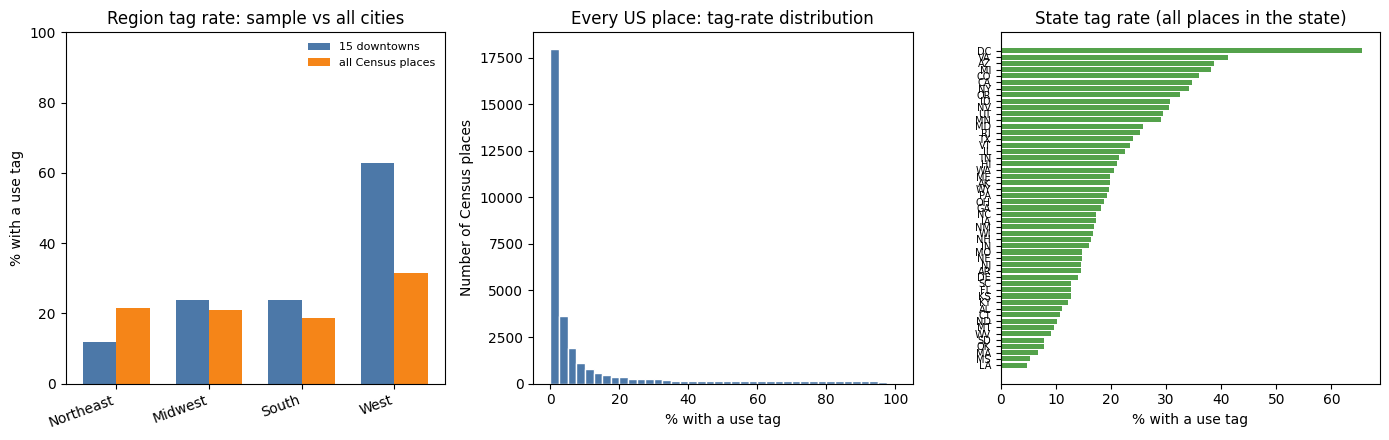

Largest places by building count:


,region,state,city,n,pct_subtype,pct_res_of_labeled,pct_study
2529,West,CA,Los Angeles,1097530,93.50,93.70,81.40
19801,Northeast,NY,New York,1091060,26.60,93.90,15.40
7220,Midwest,IL,Chicago,832358,5.60,70.20,3.20
27089,South,TX,Houston,636811,8.70,71.00,6.40
24230,Northeast,PA,Philadelphia,548263,11.20,88.80,9.90
1497,West,AZ,Phoenix,525265,65.00,88.70,58.70
27840,South,TX,San Antonio,471227,14.90,90.40,13.90
22156,South,OK,Oklahoma City,406970,6.70,81.50,5.90
26917,South,TX,Fort Worth,385997,65.70,97.60,62.10
2952,West,CA,San Diego,357820,8.90,78.00,7.20



Places with the most tagged buildings:


,region,state,city,n,n_subtype,pct_subtype,pct_res_of_labeled
2529,West,CA,Los Angeles,1097530,1025759,93.50,93.70
1497,West,AZ,Phoenix,525265,341223,65.00,88.70
19801,Northeast,NY,New York,1091060,289900,26.60,93.90
26750,South,TX,Dallas,334733,284267,84.90,92.70
26917,South,TX,Fort Worth,385997,253516,65.70,97.60
22734,West,OR,Portland,254780,215028,84.40,97.30
1627,West,AZ,Tucson,220592,199999,90.70,83.90
26153,South,TN,Memphis,246487,192853,78.20,96.50
3419,West,CO,Denver,266325,188075,70.60,79.10
29210,South,VA,Virginia Beach,207373,136595,65.90,89.70


In [25]:
# Compare the 15-downtown sample with the full city list.
fig, axes = plt.subplots(1, 3, figsize=(14, 4.5))

r15 = us_region.set_index("region").reindex(REGION_ORDER)
rall = us_all_region.set_index("region").reindex(REGION_ORDER)
x = np.arange(len(REGION_ORDER))
axes[0].bar(x - 0.18, r15["pct_subtype"], width=0.36, color="#4C78A8", label="15 downtowns")
axes[0].bar(x + 0.18, rall["pct_subtype"], width=0.36, color="#F58518", label="all Census places")
axes[0].set_xticks(x)
axes[0].set_xticklabels(REGION_ORDER, rotation=20, ha="right")
axes[0].set_ylabel("% with a use tag")
axes[0].set_ylim(0, 100)
axes[0].set_title("Region tag rate: sample vs all cities")
axes[0].legend(frameon=False, fontsize=8)

axes[1].hist(us_all_city["pct_subtype"], bins=40, color="#4C78A8", edgecolor="white")
axes[1].set_xlabel("% with a use tag")
axes[1].set_ylabel("Number of Census places")
axes[1].set_title("Every US place: tag-rate distribution")

top = us_all_state.sort_values("pct_subtype", ascending=False)
hi = top.head(8)
axes[2].barh(np.arange(len(hi)), hi["pct_subtype"], color="#54A24B")
axes[2].set_yticks(np.arange(len(hi)))
axes[2].set_yticklabels(hi["state"], fontsize=9)
axes[2].invert_yaxis()
axes[2].set_xlabel("% with a use tag")
axes[2].set_title("Highest state tag rates (top 8)")
for i, v in enumerate(hi["pct_subtype"]):
    axes[2].text(v + 0.6, i, f"{v:.0f}", va="center", fontsize=8)
axes[2].set_xlim(0, hi["pct_subtype"].max() * 1.18)
fig.tight_layout()
fig.savefig(OUT / "us_all_cities_region_state.png", dpi=150, bbox_inches="tight")
plt.show()

print("Largest places by building count:")
display(
    us_all_city.nlargest(15, "n")[
        ["region", "state", "city", "n", "pct_subtype", "pct_res_of_labeled", "pct_study"]
    ].round(1)
)
print("\nPlaces with the most tagged buildings:")
display(
    us_all_city.nlargest(15, "n_subtype")[
        ["region", "state", "city", "n", "n_subtype", "pct_subtype", "pct_res_of_labeled"]
    ].round(1)
)


**All 51 states** (the 3-panel chart only shows the top 8). Two ranked columns, colored by Census region — same tag-rate numbers, readable labels.


In [ ]:
# Clean two-column state ranking (51 labels don't fit in the 3-panel figure).
REGION_COLOR = {
    "Northeast": "#4C78A8",
    "Midwest": "#54A24B",
    "South": "#F58518",
    "West": "#B279A2",
}

st = us_all_state.sort_values("pct_subtype", ascending=False).reset_index(drop=True)
mid = int(np.ceil(len(st) / 2))
cols = [st.iloc[:mid], st.iloc[mid:]]

fig, axes = plt.subplots(1, 2, figsize=(11, 8.5), sharex=True)
for ax, part in zip(axes, cols):
    part = part.iloc[::-1]  # highest at top within the column
    y = np.arange(len(part))
    colors = [REGION_COLOR.get(r, "#999999") for r in part["region"]]
    ax.barh(y, part["pct_subtype"], color=colors, height=0.72, edgecolor="white", linewidth=0.4)
    ax.set_yticks(y)
    ax.set_yticklabels(part["state"], fontsize=9)
    ax.set_xlabel("% of buildings with a use tag")
    ax.set_xlim(0, max(st["pct_subtype"].max() * 1.18, 70))
    for yi, val in zip(y, part["pct_subtype"]):
        ax.text(val + 0.7, yi, f"{val:.0f}", va="center", fontsize=8, color="#333333")
    ax.tick_params(axis="y", length=0)
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)

axes[0].set_title("Higher tag rates")
axes[1].set_title("Lower tag rates")
handles = [
    plt.matplotlib.patches.Patch(color=c, label=name) for name, c in REGION_COLOR.items()
]
fig.legend(handles=handles, loc="lower center", ncol=4, frameon=False, bbox_to_anchor=(0.5, -0.02))
fig.suptitle("State tag rate · all Census places in the state", y=1.01, fontsize=13)
fig.tight_layout()
state_path = OUT / "us_state_tag_rate_clean.png"
fig.savefig(state_path, dpi=150, bbox_inches="tight")
print("Saved", state_path)
plt.show()


**Takeaway.** Tag rates are **state-scale**, not just city-scale: DC **66%**, VA/AZ/MI/CO/CA in the **30–40s**; LA/MS/MA in the **single digits**. Northeast/West are mixed; the Deep South is mostly sparse. A national GT set will be geographically skewed toward a handful of well-tagged states.


The histogram above is dominated by a spike at 0%, so the tail is hard to read. The plot below tells the same story in buckets: **most cities have almost no use tags; most tagged buildings sit in a small set of well-mapped cities.**


Saved /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/overture_eda/us_place_tag_rate_story.png
                     n_places  pct_places  pct_tagged
bucket                                               
Almost none\n(<5%)      21622       67.50        3.10
Sparse\n(5–20%)          5242       16.40       13.60
Partial\n(20–50%)        2461        7.70       21.20
Well tagged\n(50%+)      2704        8.40       62.00
Median city tag rate: 1.8%  ·  well-tagged cities hold 62% of tagged buildings


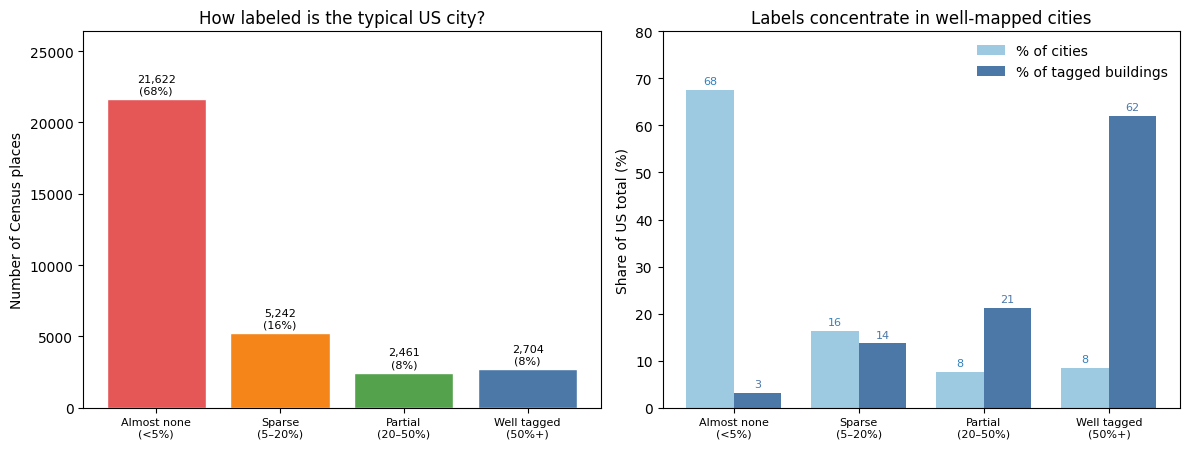

In [38]:
# Story plot: most places unlabeled; tags concentrate in a few cities.
city = us_all_city.copy()
city["bucket"] = pd.cut(
    city["pct_subtype"],
    bins=[-0.01, 5, 20, 50, 100.01],
    labels=["Almost none\n(<5%)", "Sparse\n(5–20%)", "Partial\n(20–50%)", "Well tagged\n(50%+)"],
)
bucket_order = ["Almost none\n(<5%)", "Sparse\n(5–20%)", "Partial\n(20–50%)", "Well tagged\n(50%+)"]
g = (
    city.groupby("bucket", observed=True)
    .agg(n_places=("geoid", "size"), n_buildings=("n", "sum"), n_tagged=("n_subtype", "sum"))
    .reindex(bucket_order)
)
g["pct_places"] = 100 * g["n_places"] / g["n_places"].sum()
g["pct_tagged"] = 100 * g["n_tagged"] / g["n_tagged"].sum()

fig, axes = plt.subplots(1, 2, figsize=(12, 4.6))
colors = ["#E45756", "#F58518", "#54A24B", "#4C78A8"]
x = np.arange(len(g))

axes[0].bar(x, g["n_places"], color=colors, edgecolor="white")
axes[0].set_xticks(x)
axes[0].set_xticklabels(g.index, fontsize=8)
axes[0].set_ylabel("Number of Census places")
axes[0].set_title("How labeled is the typical US city?")
for i, (n, p) in enumerate(zip(g["n_places"], g["pct_places"])):
    axes[0].text(i, n + 250, f"{int(n):,}\n({p:.0f}%)", ha="center", va="bottom", fontsize=8)
axes[0].set_ylim(0, g["n_places"].max() * 1.22)

w = 0.38
axes[1].bar(x - w / 2, g["pct_places"], width=w, color="#9ecae1", label="% of cities")
axes[1].bar(x + w / 2, g["pct_tagged"], width=w, color="#4C78A8", label="% of tagged buildings")
axes[1].set_xticks(x)
axes[1].set_xticklabels(g.index, fontsize=8)
axes[1].set_ylabel("Share of US total (%)")
axes[1].set_ylim(0, 80)
axes[1].set_title("Labels concentrate in well-mapped cities")
axes[1].legend(frameon=False, loc="upper right")
for i, (pp, pt) in enumerate(zip(g["pct_places"], g["pct_tagged"])):
    axes[1].text(i - w / 2, pp + 1.2, f"{pp:.0f}", ha="center", fontsize=8, color="#3182bd")
    axes[1].text(i + w / 2, pt + 1.2, f"{pt:.0f}", ha="center", fontsize=8, color="#4C78A8")

fig.tight_layout()
story_path = OUT / "us_place_tag_rate_story.png"
fig.savefig(story_path, dpi=150, bbox_inches="tight")
print("Saved", story_path)
print(g[["n_places", "pct_places", "pct_tagged"]].round(1))
wt = float(g["pct_tagged"].iloc[-1])
print(f"Median city tag rate: {city['pct_subtype'].median():.1f}%  ·  well-tagged cities hold {wt:.0f}% of tagged buildings")
plt.show()


**Takeaway.** The median US city has only a **1.8%** tag rate. **68%** of places are almost unlabeled (<5%), but the **8%** of places that are well tagged (≥50%) hold **~62%** of every tagged building. Use OSM labels where they exist; do not treat the unlabeled majority as negatives.


In [26]:
# Same 15 names: downtown box vs the full Census place.
SAMPLE_MATCH = [
    ("Boston", "MA", "Boston"),
    ("NYC", "NY", "New York"),
    ("Philadelphia", "PA", "Philadelphia"),
    ("Chicago", "IL", "Chicago"),
    ("Columbus", "OH", "Columbus"),
    ("Minneapolis", "MN", "Minneapolis"),
    ("Houston", "TX", "Houston"),
    ("Atlanta", "GA", "Atlanta"),
    ("Miami", "FL", "Miami"),
    ("Charlotte", "NC", "Charlotte"),
    ("SF", "CA", "San Francisco"),
    ("LA", "CA", "Los Angeles"),
    ("Seattle", "WA", "Seattle"),
    ("Denver", "CO", "Denver"),
    ("Phoenix", "AZ", "Phoenix"),
]

rows = []
for downtown, st, place in SAMPLE_MATCH:
    a = us_city.loc[(us_city["state"] == st) & (us_city["city"] == downtown)]
    b = us_all_city.loc[(us_all_city["state"] == st) & (us_all_city["city"] == place)]
    if a.empty or b.empty:
        print("missing", downtown, st, place, "downtown", len(a), "place", len(b))
        continue
    a, b = a.iloc[0], b.iloc[0]
    rows.append(
        {
            "city": downtown,
            "state": st,
            "downtown_n": int(a["n"]),
            "full_city_n": int(b["n"]),
            "downtown_% tag": a["pct_subtype"],
            "full_city_% tag": b["pct_subtype"],
            "downtown_% homes": a["pct_res_of_labeled"],
            "full_city_% homes": b["pct_res_of_labeled"],
        }
    )

cmp15 = pd.DataFrame(rows)
print(
    "Downtown boxes are smaller than the legal city. "
    "Percents can move when suburbs and the rest of the city are included."
)
display(cmp15.round(1))

print("\nUS pooled totals")
print(
    f"15 downtowns: {int(us_city['n'].sum()):,} buildings, "
    f"{100 * us_city['n_subtype'].sum() / us_city['n'].sum():.1f}% tagged"
)
print(
    f"All Census places: {int(us_all_city['n'].sum()):,} buildings, "
    f"{100 * us_all_city['n_subtype'].sum() / us_all_city['n'].sum():.1f}% tagged"
)
print(
    f"Incorporated only: {int(inc['n'].sum()):,} buildings, "
    f"{100 * inc['n_subtype'].sum() / inc['n'].sum():.1f}% tagged"
)


Downtown boxes are smaller than the legal city. Percents can move when suburbs and the rest of the city are included.


,city,state,downtown_n,full_city_n,downtown_% tag,full_city_% tag,downtown_% homes,full_city_% homes
0,Boston,MA,205813,105657,13.80,12.30,77.70,77.90
1,NYC,NY,185831,1091060,14.80,26.60,79.50,93.90
2,Philadelphia,PA,158857,548263,5.80,11.20,75.60,88.80
3,Chicago,IL,248547,832358,12.40,5.60,76.50,70.20
4,Columbus,OH,60187,319435,51.80,29.20,88.00,85.70
5,Minneapolis,MN,44861,177273,50.60,48.40,89.40,94.90
6,Houston,TX,236974,636811,12.50,8.70,79.40,71.00
7,Atlanta,GA,118893,148747,59.00,74.70,94.20,95.70
8,Miami,FL,101146,72877,8.30,8.90,82.40,81.80
9,Charlotte,NC,57928,299215,26.00,38.60,82.40,92.70



US pooled totals
15 downtowns: 2,180,691 buildings, 34.4% tagged
All Census places: 97,760,378 buildings, 23.1% tagged
Incorporated only: 79,914,797 buildings, 23.7% tagged


### Nationwide read-out

| Question | What to look at |
|---|---|
| Did the 15 downtowns stand in for the country? | Region bars: 15 downtowns vs all Census places |
| Which states have use tags? | State bar chart from every place in that state |
| Do downtown percents match the legal city? | The 15-name comparison table |
| Are CDPs different from incorporated cities? | Region table, all places vs incorporated only |

Rural buildings outside a Census place are not in these totals. That is on purpose: this is a city list, not a county or state extract.


## 9. Takeaways for GT design

| Layer | Features used | When to use |
|---|---|---|
| **A. Clean binary** | `subtype` present → residential vs other | Primary clean GT (notebook 02) |
| **B. Clean multi-class** | high-precision `class` → 10 study labels | Carbon archetypes / SOTA-style eval (notebooks 03–05) |
| **C. Weak / noisy** | Places taxonomy join; optional GHS-OBAT | Expand coverage outside well-mapped cities |
| **D. Geometry / 3D priors** | `geometry`, `height`, `num_floors` | Multi-modal joins; weak features — often sparse |
| **E. Exclude** | null subtype/class; ambiguous `residential`/`terrace` | Never as negatives |

**Expected pattern from fills:** Europe extracts ≫ US cores ≫ Lagos/Nairobi for use labels; height/floors and façade/roof tags are sparse everywhere; Places often outnumber institutional building classes.

**US coverage.** Section 8 is 15 downtowns. Section 8b is every Census place in the 50 states + DC. Use 8b for region/state claims; use 8 only as a downtown sample.


In [27]:
# Persist a compact JSON summary for downstream docs
summary = {
    "overture_release": RELEASE,
    "buildings_path": BUILDINGS,
    "places_path": PLACES,
    "cities": {k: list(v) for k, v in CITIES.items()},
    "us_hierarchy": [{**r, "bbox": list(r["bbox"])} for r in US_HIERARCHY],
    "buildings_columns": schema["column_name"].tolist(),
    "places_columns": place_schema["column_name"].tolist(),
    "subtypes": SUBTYPES,
    "class_to_label": CLASS_TO_LABEL,
    "label_order": LABEL_ORDER,
    "fill_rates": fill.reset_index().to_dict(orient="records"),
    "taxonomy_coverage": tax.reset_index().to_dict(orient="records"),
    "us_region_fill": us_region.to_dict(orient="records"),
    "us_state_fill": us_state.to_dict(orient="records"),
    "us_city_fill": us_city.to_dict(orient="records"),
    "us_all_region_fill": us_all_region.to_dict(orient="records") if "us_all_region" in dir() else [],
    "us_all_state_fill": us_all_state.to_dict(orient="records") if "us_all_state" in dir() else [],
}
with open(OUT / "overture_eda_summary.json", "w") as f:
    json.dump(summary, f, indent=2)

print("Wrote outputs to", OUT)
for p in sorted(OUT.iterdir()):
    print(f"  {p.name} ({p.stat().st_size} bytes)")


Wrote outputs to /data/users/kv133/Alpha-Earth-Embeddings-Research/outputs/overture_eda
  buildings_classes_by_city.csv (7748 bytes)
  buildings_fill_rates.csv (1855 bytes)
  buildings_schema.csv (976 bytes)
  buildings_sources_by_city.csv (689 bytes)
  buildings_subtypes_by_city.csv (2258 bytes)
  buildings_vs_places.png (62415 bytes)
  buildings_vs_places_institutions.csv (236 bytes)
  census_places_cb2024 (10 bytes)
  fill_rates_by_city.png (60770 bytes)
  height_floors_summary.csv (807 bytes)
  label_rate_by_source.png (56951 bytes)
  overture_eda_summary.json (59694 bytes)
  places_fill_and_institutions.csv (833 bytes)
  places_schema.csv (1281 bytes)
  study_class_counts.csv (3695 bytes)
  study_label_counts.csv (453 bytes)
  subtype_mix_labeled.png (65404 bytes)
  taxonomy_coverage.csv (660 bytes)
  taxonomy_coverage.png (59623 bytes)
  us_all_cities_by_name.csv (8702 bytes)
  us_all_cities_by_state (53 bytes)
  us_all_cities_extract.log (12029 bytes)
  us_all_cities_fill_rates.